# TuniShop — Data mining 05. Text mining des avis clients

**Auteure :** Sarra Abdeljaouad · **Phase :** data mining (version 1.4) · **Source :** TuniShop_DWH (vues `bi`), en direct

## Objectif

Les avis clients contiennent un commentaire libre. Ce notebook en tire ce que la note seule ne dit pas :
1. le **thème** : de quoi parle le client (livraison, qualité, emballage, service client...) ;
2. la **langue** : français ou derja tunisien écrit en arabizi (« Behi barcha », « ma3jebnich ») ;
3. la **polarité** de chaque thème, puis de l'avis : positive, neutre ou négative ;
4. la **cohérence** entre le texte et la note ;
5. la **confrontation aux faits** : un client qui se plaint d'un retard a-t-il vraiment eu un colis en retard ?

## Méthode et limite, dès le départ

L'analyse se fait **par règles** (dictionnaires de mots-clés, lexique derja), avec le module `tunishop_analytics/texte.py`, testé par `pytest`.
**Aucun modèle de sentiment ni de thèmes n'est entraîné**, et c'est un choix : les commentaires du dataset synthétique se réduisent
à une vingtaine de formulations, chacune liée à une plage de notes (section 2). Un classifieur retrouverait la note presque parfaitement :
ce serait une fuite de données, pas une performance. Un modèle de thèmes (LDA) ou des embeddings ne trouveraient rien de plus qu'un dictionnaire.

## Sorties (publiées dans TuniShop_ANALYTICS par `cfg.exporter_table`)

| Table | Une ligne par | Contenu |
|---|---|---|
| `ana.tm_avis` | avis commenté | langue, texte traduit, thèmes, polarité globale, cohérence avec la note |
| `ana.tm_avis_themes` | avis × thème | thème et sa polarité |
| `ana.tm_produits` | produit | avis commentés, part de derja, part négative, thème négatif principal, avis incohérents |
| `ana.tm_verification_faits` | thème × polarité | avis, part de colis réellement en retard, part de retours enregistrés, part de retours au motif lié |

## 0. Préparation

In [13]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, texte

warnings.filterwarnings("ignore", category=FutureWarning)
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

def pct(x, d=1):
    return f"{100 * x:.{d}f} %".replace(".", ",")

# Motifs de retour (bi.v_dim_motif_retour.motif) qui correspondent à chaque thème d'avis.
# Sert à la confrontation aux faits (section 5). Un thème absent n'a pas de motif comparable.
MOTIFS_LIES = {
    "Livraison": ["retard_livraison", "livraison_trop_tardive", "echec_livraison"],
    "Emballage": ["colis_endommage"],
    "Taille et retours": ["taille_inadaptee"],
    "Qualité produit": ["ne_correspond_pas_a_la_description", "produit_defectueux", "qualite_decevante"],
}

## 1. Données

Une requête **🔗 SQL direct** lit tous les avis dans `bi.v_fact_avis`, avec le produit et la date. Les commentaires du DWH
ont déjà été nettoyés par le staging ; `texte.nettoyer` repasse quand même dessus (sans effet sur un texte propre).

In [14]:
chargement.ouvrir_connexion()
avis = sql("""
    SELECT a.avis_id, a.commande_id, a.client_sk, p.produit_id, p.categorie,
           d.[date] AS date_avis, a.note, a.sentiment, a.a_commentaire, a.commentaire
    FROM bi.v_fact_avis a
    JOIN bi.v_dim_produit p ON p.produit_sk = a.produit_sk
    JOIN bi.v_dim_date d    ON d.date_sk    = a.date_avis_sk
""")
avis["date_avis"] = pd.to_datetime(avis["date_avis"])
print(f"avis : {len(avis):,} lignes, dont {int(avis['a_commentaire'].sum()):,} avec commentaire".replace(",", " "))
print("notes :", avis["note"].value_counts().sort_index().to_dict())
print("sentiment (colonne du DWH, déduite de la note) :", avis["sentiment"].value_counts().to_dict())

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
avis : 9 314 lignes  dont 6 081 avec commentaire
notes : {1.0: 532, 2.0: 588, 3.0: 1160, 4.0: 2604, 5.0: 4420}
sentiment (colonne du DWH, déduite de la note) : {'positif': 7024, 'neutre': 1160, 'negatif': 1120}


In [15]:
# 🔗 Contrôle SQL direct : le tableau chargé correspond au DWH
ctrl = sql("SELECT COUNT(*) AS avis, SUM(CAST(a_commentaire AS INT)) AS avec_commentaire FROM bi.v_fact_avis")
ctrl["chargé (avis)"] = len(avis)
ctrl["chargé (avec commentaire)"] = int(avis["a_commentaire"].sum())
ctrl["statut"] = np.where((ctrl["avis"] == len(avis)) & (ctrl["avec_commentaire"] == avis["a_commentaire"].sum()), "OK", "ÉCART")
ctrl

,avis,avec_commentaire,chargé (avis),chargé (avec commentaire),statut
0,9314,6081,9314,6081,OK


## 2. Ce que contiennent les commentaires

In [16]:
commentes = avis[avis["a_commentaire"] == 1].copy()
commentes["texte_nettoye"] = commentes["commentaire"].map(texte.nettoyer)
commentes = commentes[commentes["texte_nettoye"].notna()]

formulations = (commentes.groupby("texte_nettoye")
                .agg(avis=("avis_id", "size"), note_min=("note", "min"), note_max=("note", "max"), note_moyenne=("note", "mean"))
                .sort_values("avis", ascending=False))
formulations["langue"] = formulations.index.map(texte.detecter_langue)
print(f"{len(commentes):,} commentaires, {len(formulations)} formulations différentes".replace(",", " "))
formulations.round(2)

6 081 commentaires  19 formulations différentes


,avis,note_min,note_max,note_moyenne,langue
texte_nettoye,,,,,
"Mriguel, merci TuniShop.",600,4.000,5.000,4.610,derja
"Très satisfait, produit conforme et livraison rapide.",582,4.000,5.000,4.630,français
"Excellent rapport qualité/prix, je recommande.",580,4.000,5.000,4.640,français
"Behi barcha, livraison fi wa9tha.",577,4.000,5.000,4.610,derja
"Conforme à la photo, très contente.",577,4.000,5.000,4.640,français
"Produit de bonne qualité, emballage soigné.",577,4.000,5.000,4.670,français
"Deuxième commande, toujours aussi satisfait.",563,4.000,5.000,4.640,français
"Rien à dire, parfait !",535,4.000,5.000,4.610,français
Bon produit mais emballage abîmé.,205,3.000,3.000,3.000,français


> **Lecture.** 6 081 avis sur 9 314 ont un commentaire (65 %), mais il n'existe que **19 formulations différentes**.
> Chacune reste dans une plage de notes fixe : les 8 formulations positives n'apparaissent qu'avec les notes 4 et 5,
> les 4 formulations neutres qu'avec la note 3, les 7 négatives qu'avec les notes 1 et 2. Le texte est donc
> **généré à partir de la note**. 1 274 commentaires sont en derja (21 %) : « Mriguel », « Behi barcha » et « Khayeb, ma3jebnich ».

## 3. Thèmes, langue et polarité

`texte.analyser_avis` découpe chaque commentaire (virgules, points, « mais »), cherche les thèmes par mots-clés et donne
une polarité à chacun. Chaque formulation distincte n'est analysée qu'une fois.

In [17]:
themes = texte.analyser_avis(commentes, col_texte="commentaire")     # une ligne par (avis, thème)

par_avis = themes.groupby("avis_id").apply(lambda g: list(zip(g["theme"], g["polarite"])), include_groups=False)
tm_avis = commentes.drop(columns=["commentaire", "a_commentaire"]).rename(columns={"sentiment": "sentiment_dwh"})
tm_avis["langue"] = tm_avis["texte_nettoye"].map(texte.detecter_langue)
tm_avis["texte_fr"] = np.where(tm_avis["langue"] == "derja", tm_avis["texte_nettoye"].map(texte.traduire_derja), tm_avis["texte_nettoye"])
tm_avis["couples"] = tm_avis["avis_id"].map(par_avis).apply(lambda v: v if isinstance(v, list) else [])
tm_avis["themes"] = tm_avis["couples"].map(lambda v: "; ".join(t for t, _ in v))
tm_avis["nb_themes"] = tm_avis["couples"].map(len)
tm_avis["polarite_globale"] = tm_avis["couples"].map(texte.polarite_globale)
tm_avis["coherence"] = [texte.coherence(n, p) for n, p in zip(tm_avis["note"], tm_avis["polarite_globale"])]
tm_avis = tm_avis.drop(columns="couples")

sans_theme = (tm_avis["nb_themes"] == 0).sum()
print(f"avis commentés analysés : {len(tm_avis):,} ; sans thème reconnu : {sans_theme}".replace(",", " "))
print("langue :", tm_avis["langue"].value_counts(normalize=True).round(3).to_dict())

volume = (themes.pivot_table(index="theme", columns="polarite", values="avis_id", aggfunc="count", fill_value=0)
          .reindex(columns=["positif", "neutre", "négatif"], fill_value=0))
volume["total"] = volume.sum(axis=1)
volume = volume.sort_values("total", ascending=False)
volume

avis commentés analysés : 6 081 ; sans thème reconnu : 0
langue : {'français': 0.79, 'derja': 0.21}


polarite,positif,neutre,négatif,total
theme,,,,
Satisfaction générale,3451,364,190,4005
Qualité produit,1941,180,214,2335
Livraison,1159,0,401,1560
Emballage,577,0,205,782
Prix,580,0,0,580
Fidélité,563,0,0,563
Taille et retours,0,0,105,105
Service client,0,0,104,104


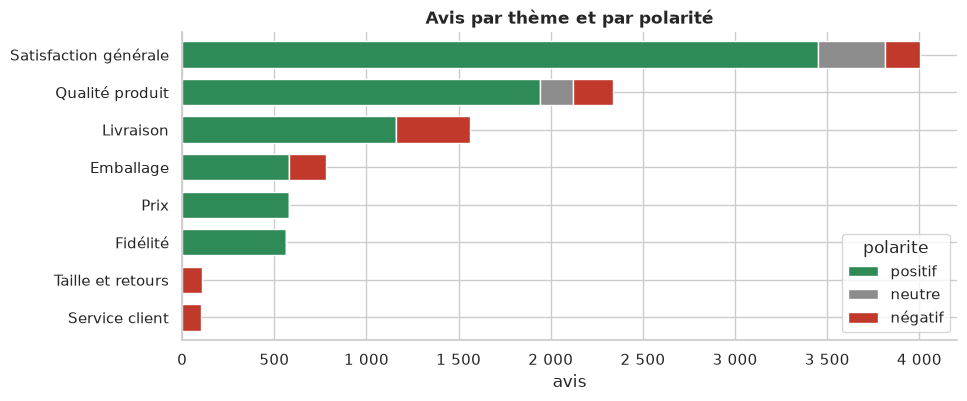

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
volume[["positif", "neutre", "négatif"]].iloc[::-1].plot.barh(stacked=True, ax=ax,
                                                         color=[cfg.VERT, cfg.GRIS, cfg.ROUGE], width=0.7)
ax.set_title("Avis par thème et par polarité"); ax.set_xlabel("avis"); ax.set_ylabel("")
cfg.format_milliers(ax, "x")
montrer("DM05_themes_polarite")

> **Lecture.** Tous les commentaires reçoivent au moins un thème (10 034 couples avis × thème). Les plus cités sont la
> satisfaction générale (4 005 avis), la qualité du produit (2 335) et la livraison (1 560). En volume, la livraison
> porte le plus de critiques précises (401 avis négatifs), devant la qualité (214) et l'emballage (205). La taille
> (105) et le service client (104) ne sont cités qu'en négatif. Au niveau de l'avis : 4 591 positifs, 569 neutres
> (souvent mixtes, comme « Bon produit mais emballage abîmé ») et 921 négatifs. Le derja est surtout positif
> (1 177 avis sur 1 274).

## 4. Cohérence entre le texte et la note

Un texte positif avec une note de 1 ou 2, ou un texte négatif avec une note de 4 ou 5, est signalé. Un avis mixte
(« Bon produit mais emballage abîmé ») a une polarité globale **neutre** et n'est jamais signalé.

In [19]:
coh = pd.crosstab(tm_avis["polarite_globale"].fillna("sans thème"), tm_avis["note"], margins=True, margins_name="total")
print(tm_avis["coherence"].value_counts().to_dict())
coh

{'cohérent': 6075, 'non évaluable': 6}


note,1.000,2.000,3.000,4.000,5.000,total
polarite_globale,,,,,,
neutre,0,0,569,0,0,569
négatif,363,377,180,0,0,920
positif,0,0,0,1688,2898,4586
total,363,377,749,1688,2898,6075


## 5. Confrontation aux faits : le texte décrit-il ce qui s'est passé ?

Pour chaque avis, deux faits sont lus dans le DWH :
- **colis en retard** : au moins une livraison de la commande avec `retard_j > 0` (`bi.v_fact_livraisons`) ;
- **retour enregistré** : un remboursement pour la même commande et le même produit (`bi.v_fact_remboursements`),
  et s'il a un **motif lié** au thème (dictionnaire `MOTIFS_LIES` de la préparation).

Si les avis décrivaient l'expérience vécue, un avis « livraison négatif » aurait bien plus de colis en retard que les autres.

In [20]:
livraisons = sql("""
    SELECT commande_id,
           MAX(CASE WHEN retard_j > 0 THEN 1 ELSE 0 END) AS colis_en_retard
    FROM bi.v_fact_livraisons
    GROUP BY commande_id
""")
retours = sql("""
    SELECT r.commande_id, p.produit_id, m.motif
    FROM bi.v_fact_remboursements r
    JOIN bi.v_dim_produit p      ON p.produit_sk      = r.produit_sk
    JOIN bi.v_dim_motif_retour m ON m.motif_retour_sk = r.motif_retour_sk
""")
motifs_par_ligne = retours.groupby(["commande_id", "produit_id"])["motif"].agg(set)
print(f"commandes livrées suivies : {len(livraisons):,} ; retours : {len(retours):,}".replace(",", " "))

# themes contient déjà la commande et le produit de chaque avis (colonnes reprises de commentes)
faits = themes[["avis_id", "theme", "polarite", "commande_id", "produit_id"]].merge(livraisons, on="commande_id", how="left")
cle = list(zip(faits["commande_id"], faits["produit_id"]))
motifs = [motifs_par_ligne.get(k, set()) for k in cle]
faits["retour"] = [int(bool(m)) for m in motifs]
faits["retour_motif_lie"] = [
    (int(bool(m & set(MOTIFS_LIES[t]))) if t in MOTIFS_LIES else np.nan) for m, t in zip(motifs, faits["theme"])]

def resumer(g):
    return pd.Series({"avis": g["avis_id"].nunique(),
                      "part_colis_en_retard": g["colis_en_retard"].mean(),
                      "part_retour": g["retour"].mean(),
                      "part_retour_motif_lie": g["retour_motif_lie"].mean()})

verif = faits.groupby(["theme", "polarite"]).apply(resumer, include_groups=False).reset_index()
verif["motifs_lies"] = verif["theme"].map(lambda t: ", ".join(MOTIFS_LIES.get(t, [])))

# Lignes de référence : tous les avis commentés, et tous les avis (avec ou sans commentaire)
ref_c = avis[avis["a_commentaire"] == 1][["avis_id", "commande_id", "produit_id"]]
ref_t = avis[["avis_id", "commande_id", "produit_id"]]
lignes_ref = []
for nom, r in [("Tous les avis commentés", ref_c), ("Tous les avis", ref_t)]:
    r = r.merge(livraisons, on="commande_id", how="left")
    r["retour"] = [int(bool(motifs_par_ligne.get(k, set()))) for k in zip(r["commande_id"], r["produit_id"])]
    lignes_ref.append({"theme": nom, "polarite": "toutes", "avis": len(r),
                       "part_colis_en_retard": r["colis_en_retard"].mean(), "part_retour": r["retour"].mean(),
                       "part_retour_motif_lie": np.nan, "motifs_lies": ""})
tm_verification_faits = pd.concat([verif, pd.DataFrame(lignes_ref)], ignore_index=True)
tm_verification_faits["avis"] = tm_verification_faits["avis"].astype(int)
tm_verification_faits.style.format({"part_colis_en_retard": "{:.1%}", "part_retour": "{:.1%}", "part_retour_motif_lie": "{:.1%}"}, na_rep="")

commandes livrées suivies : 61 793 ; retours : 8 815


,theme,polarite,avis,part_colis_en_retard,part_retour,part_retour_motif_lie,motifs_lies
0,Emballage,négatif,205,35.1%,16.6%,1.5%,colis_endommage
1,Emballage,positif,577,16.1%,7.6%,0.0%,colis_endommage
2,Fidélité,positif,563,14.2%,5.5%,,
3,Livraison,négatif,401,26.7%,31.4%,0.2%,"retard_livraison, livraison_trop_tardive, echec_livraison"
4,Livraison,positif,1159,13.0%,7.9%,0.0%,"retard_livraison, livraison_trop_tardive, echec_livraison"
5,Prix,positif,580,16.6%,6.2%,,
6,Qualité produit,neutre,180,27.2%,23.9%,12.8%,"ne_correspond_pas_a_la_description, produit_defectueux, qualite_decevante"
7,Qualité produit,négatif,214,30.4%,35.0%,23.8%,"ne_correspond_pas_a_la_description, produit_defectueux, qualite_decevante"
8,Qualité produit,positif,1941,17.3%,8.7%,0.9%,"ne_correspond_pas_a_la_description, produit_defectueux, qualite_decevante"
9,Satisfaction générale,neutre,364,36.0%,15.7%,,


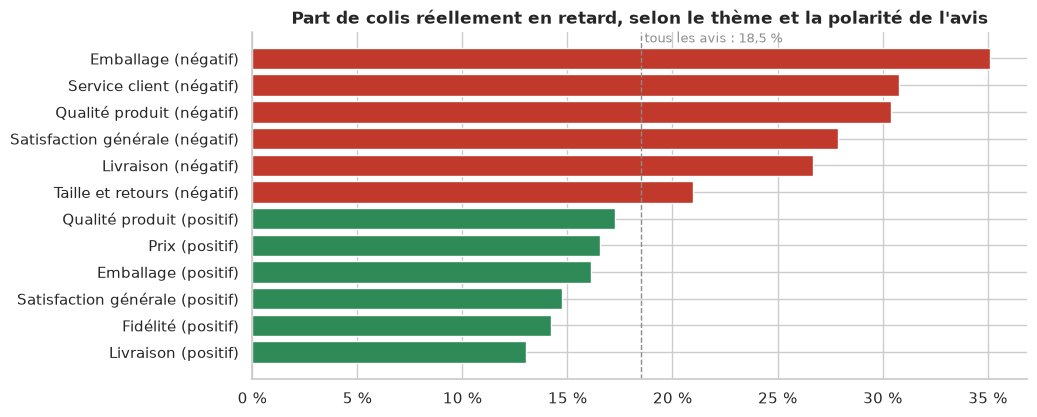

In [21]:
neg = tm_verification_faits[tm_verification_faits["polarite"].isin(["négatif", "positif"])].copy()
neg["libelle"] = neg["theme"] + " (" + neg["polarite"] + ")"
neg = neg.sort_values("part_colis_en_retard")
base = tm_verification_faits.loc[tm_verification_faits["theme"] == "Tous les avis", "part_colis_en_retard"].iat[0]

fig, ax = plt.subplots(figsize=(10, 4.5))
couleurs = [cfg.ROUGE if p == "négatif" else cfg.VERT for p in neg["polarite"]]
ax.barh(neg["libelle"], neg["part_colis_en_retard"], color=couleurs)
ax.axvline(base, color=cfg.GRIS, linestyle="--", linewidth=1)
ax.text(base, len(neg) - 0.4, f" tous les avis : {pct(base)}", color=cfg.GRIS, fontsize=9)
ax.set_title("Part de colis réellement en retard, selon le thème et la polarité de l'avis")
cfg.format_pourcent(ax, "x")
montrer("DM05_confrontation_faits")

> **Lecture.** Les avis négatifs ont bien plus de colis en retard (21 à 35 %) que les positifs (13 à 17 %, contre
> 18,5 % pour l'ensemble des avis), et beaucoup plus de retours (17 à 40 %, contre 6 à 9 %). Mais le **thème** ne
> correspond pas aux faits. Un avis qui se plaint de la livraison a 26,7 % de colis en retard, **moins** qu'un avis
> négatif sur l'emballage (35,1 %) ou le service client (30,8 %). « Taille trop petite » n'a que 1,9 % de retours pour
> taille, « Emballage abîmé » 1,5 % pour colis endommagé, et « Livraison » 0,2 % de retours pour un motif de livraison.
> Seule la qualité garde un lien (23,8 % de retours au motif lié, contre 0,9 % pour les avis positifs), mais ses 3
> motifs sont larges. **Le texte suit la note, pas l'expérience vécue** : le générateur a choisi la phrase selon la
> note. Ce résultat montre que les données sont vérifiées au lieu d'être crues. Sur des avis réels, la même table
> dirait si les plaintes reflètent de vrais problèmes.

## 6. Synthèse par produit

In [22]:
base_p = avis.groupby("produit_id").agg(categorie=("categorie", "first"), nb_avis=("avis_id", "size"),
                                        note_moyenne=("note", "mean"))
c = tm_avis.groupby("produit_id")
synth = pd.DataFrame({
    "nb_commentes": c.size(),
    "part_derja": c["langue"].apply(lambda s: (s == "derja").mean()),
    "part_positif": c["polarite_globale"].apply(lambda s: (s == "positif").mean()),
    "part_negatif": c["polarite_globale"].apply(lambda s: (s == "négatif").mean()),
    "nb_incoherents": c["coherence"].apply(lambda s: s.str.startswith("texte").sum()),
})
theme_neg = (faits[faits["polarite"] == "négatif"].groupby(["produit_id", "theme"]).size()
             .reset_index(name="n").sort_values(["produit_id", "n", "theme"], ascending=[True, False, True])
             .drop_duplicates("produit_id").set_index("produit_id")["theme"])
tm_produits = base_p.join(synth, how="left")
tm_produits["nb_commentes"] = tm_produits["nb_commentes"].fillna(0).astype(int)
tm_produits["nb_incoherents"] = tm_produits["nb_incoherents"].fillna(0).astype(int)
tm_produits["theme_negatif_principal"] = theme_neg
tm_produits = tm_produits.reset_index()
print(f"{len(tm_produits)} produits avec au moins un avis")
tm_produits.sort_values("part_negatif", ascending=False).head(10).round(3)

553 produits avec au moins un avis


,produit_id,categorie,nb_avis,note_moyenne,nb_commentes,part_derja,part_positif,part_negatif,nb_incoherents,theme_negatif_principal
474,PRD0513,Bébé & Enfants,2,2.500,1,0.000,0.000,1.000,0,Qualité produit
425,PRD0461,Maison & Cuisine,2,2.000,2,0.000,0.000,1.000,0,Livraison
229,PRD0261,Mode,1,2.000,1,0.000,0.000,1.000,0,Service client
147,PRD0174,Électroménager,2,3.500,1,0.000,0.000,1.000,0,Livraison
7,PRD0009,Électronique & High-Tech,1,1.000,1,0.000,0.000,1.000,0,Livraison
114,PRD0134,Électronique & High-Tech,2,3.500,1,0.000,0.000,1.000,0,Taille et retours
56,PRD0064,Électronique & High-Tech,3,4.000,1,0.000,0.000,1.000,0,Livraison
299,PRD0334,Mode,3,4.000,1,0.000,0.000,1.000,0,Livraison
48,PRD0056,Électronique & High-Tech,1,1.000,1,0.000,0.000,1.000,0,Service client
397,PRD0433,Maison & Cuisine,2,2.500,1,1.000,0.000,1.000,0,Satisfaction générale


## 7. Publication

`cfg.exporter_table` écrit le CSV dans `06_Exports/Tables` **et** la table `ana.<nom>` de TuniShop_ANALYTICS
(vider puis remplir en une transaction, trace dans `ctl.journal_publication`). Les clés uniques sont contrôlées par
`publication.CLES` avant l'écriture.

In [23]:
colonnes_avis = ["avis_id", "commande_id", "client_sk", "produit_id", "categorie", "date_avis", "note", "sentiment_dwh",
                 "langue", "texte_nettoye", "texte_fr", "themes", "nb_themes", "polarite_globale", "coherence"]
tm_avis_themes = themes[["avis_id", "theme", "polarite", "langue"]]
colonnes_verif = ["theme", "polarite", "avis", "part_colis_en_retard", "part_retour", "motifs_lies", "part_retour_motif_lie"]
colonnes_prod = ["produit_id", "categorie", "nb_avis", "note_moyenne", "nb_commentes", "part_derja",
                 "part_positif", "part_negatif", "theme_negatif_principal", "nb_incoherents"]

cfg.exporter_table(tm_avis[colonnes_avis], "TM_avis", index=False)
cfg.exporter_table(tm_avis_themes, "TM_avis_themes", index=False)
cfg.exporter_table(tm_produits[colonnes_prod], "TM_produits", index=False)
cfg.exporter_table(tm_verification_faits[colonnes_verif], "TM_verification_faits", index=False)

# Contrôle : une ligne par avis commenté, aucun avis perdu
assert tm_avis["avis_id"].is_unique
assert tm_avis_themes["avis_id"].isin(tm_avis["avis_id"]).all()
print("Publication terminée : 4 tables ana.tm_*")

  ✔ ana.tm_avis                                   6 081 lignes
  ✔ ana.tm_avis_themes                           10 034 lignes
  ✔ ana.tm_produits                                 553 lignes
  ✔ ana.tm_verification_faits                        16 lignes
Publication terminée : 4 tables ana.tm_*


## 8. Synthèse

> **Lecture.** Le text mining classe les 6 081 commentaires en 8 thèmes, repère le derja (21 %) et donne une polarité
> à chaque thème. Aucun avis n’est incohérent avec sa note (6 075 cohérents ; 6 sans note valide, donc non évaluables), ce qui confirme que le texte est généré à partir de la note.
> La confrontation aux faits le prouve : les avis négatifs ont plus de retards et de retours, mais presque
> jamais pour la raison qu'ils citent (1,9 % pour la taille, 1,5 % pour l'emballage, 0,2 % pour la livraison).
>
> **Ce que ce notebook montre.** Une chaîne de text mining complète et testée (nettoyage, derja, thèmes, polarité),
> et surtout une **vérification** : on ne croit pas le texte, on le confronte aux faits du DWH.
>
> **Ce qu'il ne faut pas en conclure.** Les commentaires sont synthétiques : leurs proportions disent comment le
> générateur a été écrit, pas ce que pensent de vrais clients. Sur des avis réels, la méthode s'applique telle quelle ;
> seuls les dictionnaires seraient à enrichir.

In [25]:
chargement.fermer_connexion()